## Implementation of Linear regression using python

In [24]:
### import required libraries
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error,r2_score
import matplotlib.pyplot as plt


In [25]:
%pip install numpy pandas

Note: you may need to restart the kernel to use updated packages.


## Load the dataset

In [26]:
DF1=pd.read_csv("weight-height.csv")
DF1.head()

,Gender,Height,Weight
0,Male,73.847017,241.893563
1,Male,68.781904,162.310473
2,Male,74.110105,212.740856
3,Male,71.730978,220.042470
4,Male,69.881796,206.349801


### Standardize numerical features

In [27]:
col=["Height","Weight"]
S1=MinMaxScaler()
DF1[col]=S1.fit_transform(DF1[col])
DF1.head()

,Gender,Height,Weight
0,Male,0.165212,0.863139
1,Male,0.122482,0.475476
2,Male,0.167432,0.721131
3,Male,0.147361,0.756699
4,Male,0.131761,0.689999


## Prepare dependant and independant variables

In [28]:
X=DF1[["Height"]].to_numpy()
Y=DF1[["Weight"]].to_numpy()
Y.shape

(10000, 1)

In [29]:
X.shape

(10000, 1)

## Split the data into training and test set

In [30]:
 X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=.2,random_state=67)

In [31]:
# Create a linear regression model

model=LinearRegression()



Note: Learning more about Linear Regression model here: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html 



In [32]:
## Training  Linear regressions model 

In [33]:
model.fit(X_train,Y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[3.55]]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[0.11]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[3.28]


In [34]:
## Calculating the Mean Squared Error (MSE) and R-squared (R2)
Y_pred=model.predict(X_test)
mse=mean_squared_error(Y_test,Y_pred)
rmse = mean_squared_error(Y_test, Y_pred) ** 0.5
mae = mean_absolute_error(Y_test, Y_pred)
r2=r2_score(Y_test,Y_pred)
print(mse)
print(rmse)
print(mae)
print(r2)

# Print model coefficients
print(model.coef_[0])
print(model.intercept_)

0.0044380478890117024
0.06661867522708405
0.054480150433493836
0.8135299373473699
[3.54709605]
[0.10829265]


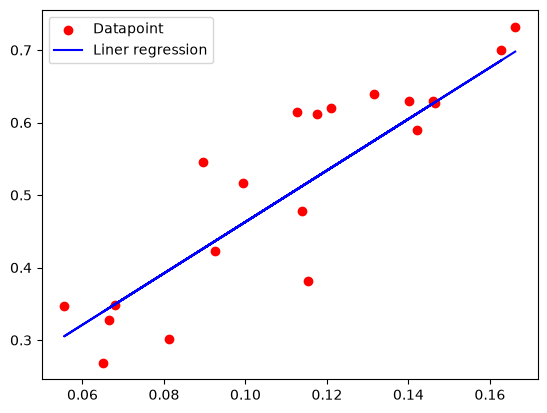

In [35]:
# Plot the linear regression Model 
plt.scatter(X_test[0:20],Y_test[0:20],color="Red",label="Datapoint")
plt.plot(X_test[0:20],Y_pred[0:20],color="Blue",label="Liner regression")
plt.legend()


In [36]:
df2=pd.read_csv("weight-height.csv")
X = df2['Height'].values.reshape(-1, 1)
X.shape
Y=df2["Weight"].values
print(X.shape)
print(Y.shape)

(10000, 1)
(10000,)


### Z-Score Normalization

The Z-score normalization formula is:

$$
z = \frac{x-\mu}{\sigma}
$$

Where:
- $x$ = Original data value
- $\mu$ = Mean of the dataset
- $\sigma$ = Standard deviation of the dataset
- $z$ = Normalized Z-score

In [37]:
## Standardizes the features X and target variable y using Z-score normalization (also called Standardization). 
X = (X - np.mean(X, axis=0)) / np.std(X, axis=0)
Y = (Y - np.mean(Y, axis=0)) / np.std(Y, axis=0)


[![Single-Input-Linear-Neuron-Diagram.png](https://i.postimg.cc/PxYWMz4F/Single-Input-Linear-Neuron-Diagram.png)](https://postimg.cc/vg8xYnCW)

In [38]:
#add another feature to X corresponding to bias
X = np.hstack((np.ones((X.shape[0], 1)), X))
X

array([[ 1.        ,  1.75827913],
       [ 1.        ,  0.56277158],
       [ 1.        ,  1.82037531],
       ...,
       [ 1.        , -0.59704831],
       [ 1.        , 24.22511229],
       [ 1.        , -1.05110595]], shape=(10000, 2))

In [39]:
#weight or parameter initialization
theta = np.zeros(X.shape[1])
iterations=1000
# Hyperparameters
learningrate=0.01
# Gradient Descent
mseh=[]
print(X.shape)
m=X.T
print(m.shape)
print(Y_pred.shape)

(10000, 2)
(2, 10000)
(2000, 1)


<img src="https://i.postimg.cc/wMYVXD65/1.png" alt="Image Description" width="500">

In [40]:
 for i in range(iterations):
    y_pred = np.dot(X, theta)
    mse = mean_squared_error(Y, y_pred)
    mseh.append(mse)

    print(f"Iteration {i+1}: MSE = {mse}")

    gradient = np.dot(X.T, (y_pred - Y)) / len(Y)
    theta = theta-learningrate * gradient

Iteration 1: MSE = 1.0
Iteration 2: MSE = 0.985809419277575
Iteration 3: MSE = 0.9719012311115264
Iteration 4: MSE = 0.9582698158899818
Iteration 5: MSE = 0.9449096658313463
Iteration 6: MSE = 0.9318153827588774
Iteration 7: MSE = 0.9189816759195508
Iteration 8: MSE = 0.9064033598463267
Iteration 9: MSE = 0.8940753522629599
Iteration 10: MSE = 0.8819926720305018
Iteration 11: MSE = 0.87015043713467
Iteration 12: MSE = 0.8585438627132649
Iteration 13: MSE = 0.847168259122846
Iteration 14: MSE = 0.8360190300438766
Iteration 15: MSE = 0.8250916706235781
Iteration 16: MSE = 0.8143817656557442
Iteration 17: MSE = 0.8038849877967698
Iteration 18: MSE = 0.7935970958171891
Iteration 19: MSE = 0.7835139328880019
Iteration 20: MSE = 0.7736314249011057
Iteration 21: MSE = 0.7639455788231487
Iteration 22: MSE = 0.7544524810821431
Iteration 23: MSE = 0.7451482959861835
Iteration 24: MSE = 0.7360292641736333
Iteration 25: MSE = 0.727091701094153
Iteration 26: MSE = 0.7183319955199544
Iteration 27: M

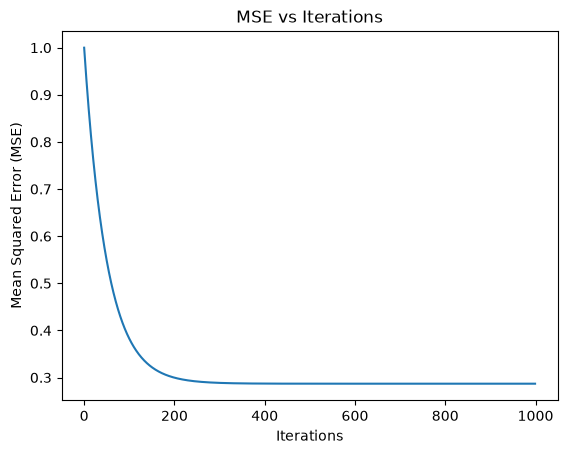

In [41]:
plt.plot(range(len(mseh)), mseh)
plt.xlabel('Iterations')
plt.ylabel('Mean Squared Error (MSE)')
plt.title('MSE vs Iterations')
plt.show()

In [42]:
print(theta)

[1.30148203e-15 8.44412778e-01]


## You are required to fit a linear function on Food_delivery_times dataset
Description about the dataset: This dataset is designed for predicting food delivery times based on various influencing factors such as distance, weather, traffic conditions, and Preperation time. 
1. Feature selection: Consider Food_delivery_time is effected by four features (attributes) given in the dataset, which are Distance_km, Preparation_Time_min, Traffic, Weather
2. Since Traffic, Weather are having categorical values, you need to convert them into numerical using the categorical encoding methods.
3. Now, fit a linear regression model considering Distance_km, Preparation_Time_min, Traffic, and Weather as independant variables and Delivery_Time_min as dependant varibal. 


Note: In lab record, you can write the statements relevant to linear regression.

In [43]:
DF3 = pd.read_csv("Food_Delivery_Times.csv")
DF3.head()

,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43
1,738,16.42,Clear,Medium,Evening,Bike,20,2.0,84
2,741,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37
4,412,19.03,Clear,Low,Morning,Bike,16,5.0,68


In [44]:

# Select the four features mentioned in the question
X = DF3[["Distance_km", "Preparation_Time_min", "Traffic_Level", "Weather"]].copy()
Y = DF3["Delivery_Time_min"].to_numpy()

print("Independent variables:")
display(X.head())
print("Dependent variable shape:", Y.shape)

Independent variables:


,Distance_km,Preparation_Time_min,Traffic_Level,Weather
0,7.93,12,Low,Windy
1,16.42,20,Medium,Clear
2,9.52,28,Low,Foggy
3,7.44,5,Medium,Rainy
4,19.03,16,Low,Clear


Dependent variable shape: (1000,)


In [45]:
# Traffic_Level and Weather are categorical, so use one-hot encoding
X = pd.get_dummies(X, columns=["Traffic_Level", "Weather"], dtype=int)
X.head()

,Distance_km,Preparation_Time_min,Traffic_Level_High,Traffic_Level_Low,Traffic_Level_Medium,Weather_Clear,Weather_Foggy,Weather_Rainy,Weather_Snowy,Weather_Windy
0,7.93,12,0,1,0,0,0,0,0,1
1,16.42,20,0,0,1,1,0,0,0,0
2,9.52,28,0,1,0,0,1,0,0,0
3,7.44,5,0,0,1,0,0,1,0,0
4,19.03,16,0,1,0,1,0,0,0,0


In [46]:
X = X.to_numpy(dtype=float)
Y = Y.astype(float)
print("X shape:", X.shape)
print("Y shape:", Y.shape)

X shape: (1000, 10)
Y shape: (1000,)


In [47]:

# Standardize the independent variables and dependent variable
X = (X - np.mean(X, axis=0)) / np.std(X, axis=0)
Y = (Y - np.mean(Y, axis=0)) / np.std(Y, axis=0)

print("Standardized X shape:", X.shape)
print("Standardized Y shape:", Y.shape)

Standardized X shape: (1000, 10)
Standardized Y shape: (1000,)


In [48]:
X = np.hstack((np.ones((X.shape[0], 1)), X))
print("X shape after adding bias:", X.shape)
X[:5]

X shape after adding bias: (1000, 11)


array([[ 1.        , -0.37408542, -0.69185319, -0.495308  ,  1.26923838,
        -0.79959006, -0.94169658, -0.33886163, -0.50624244, -0.32774947,
         3.06865877],
       [ 1.        ,  1.11700846,  0.41911139, -0.495308  , -0.78787407,
         1.25064086,  1.06191317, -0.33886163, -0.50624244, -0.32774947,
        -0.32587527],
       [ 1.        , -0.09483462,  1.53007597, -0.495308  ,  1.26923838,
        -0.79959006, -0.94169658,  2.95105708, -0.50624244, -0.32774947,
        -0.32587527],
       [ 1.        , -0.46014384, -1.6639472 , -0.495308  , -0.78787407,
         1.25064086, -0.94169658, -0.33886163,  1.97533814, -0.32774947,
        -0.32587527],
       [ 1.        ,  1.57540128, -0.1363709 , -0.495308  ,  1.26923838,
        -0.79959006,  1.06191317, -0.33886163, -0.50624244, -0.32774947,
        -0.32587527]])

In [49]:
theta = np.zeros(X.shape[1])
iterations = 1000
learningrate = 0.01
mseh = []

print("Initial theta:", theta)
print("X shape:", X.shape)
print("Number of parameters:", len(theta))

Initial theta: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
X shape: (1000, 11)
Number of parameters: 11


In [50]:
for i in range(iterations):
    Y_pred = np.dot(X, theta)
    mse = mean_squared_error(Y, Y_pred)
    mseh.append(mse)
    print(f"iteration {i+1}: MSE = {mse}")
    gradient = np.dot(X.T, (Y_pred - Y)) / len(Y)
    theta = theta - learningrate * gradient

print("Final theta values:", theta)

iteration 1: MSE = 0.9999999999999998
iteration 2: MSE = 0.9838493522555725
iteration 3: MSE = 0.9680479213400158
iteration 4: MSE = 0.9525878867584363
iteration 5: MSE = 0.937461610411654
iteration 6: MSE = 0.9226616321490713
iteration 7: MSE = 0.9081806654350078
iteration 8: MSE = 0.8940115931254784
iteration 9: MSE = 0.8801474633524767
iteration 10: MSE = 0.8665814855129046
iteration 11: MSE = 0.8533070263593677
iteration 12: MSE = 0.840317606190136
iteration 13: MSE = 0.8276068951356399
iteration 14: MSE = 0.8151687095389486
iteration 15: MSE = 0.802997008427743
iteration 16: MSE = 0.791085890075368
iteration 17: MSE = 0.7794295886486131
iteration 18: MSE = 0.7680224709399381
iteration 19: MSE = 0.7568590331819149
iteration 20: MSE = 0.7459338979417314
iteration 21: MSE = 0.7352418110936462
iteration 22: MSE = 0.7247776388673559
iteration 23: MSE = 0.71453636497028
iteration 24: MSE = 0.704513087781832
iteration 25: MSE = 0.6947030176177913
iteration 26: MSE = 0.6851014740629473
it

In [51]:
# Predictions are in standardized units, so convert them back to minutes
Y_pred_standardized = np.dot(X, theta)
Y_pred = Y_pred_standardized * np.std(DF3["Delivery_Time_min"].to_numpy()) + np.mean(DF3["Delivery_Time_min"].to_numpy())
Y_actual = DF3["Delivery_Time_min"].to_numpy()

print("Mean Squared Error (MSE):", mean_squared_error(Y_actual, Y_pred))
print("Root Mean Squared Error (RMSE):", mean_squared_error(Y_actual, Y_pred) ** 0.5)
print("Mean Absolute Error (MAE):", mean_absolute_error(Y_actual, Y_pred))
print("R-squared (R2):", r2_score(Y_actual, Y_pred))

Mean Squared Error (MSE): 112.37051170046604
Root Mean Squared Error (RMSE): 10.60049582333138
Mean Absolute Error (MAE): 6.677239568096571
R-squared (R2): 0.7690881701388219


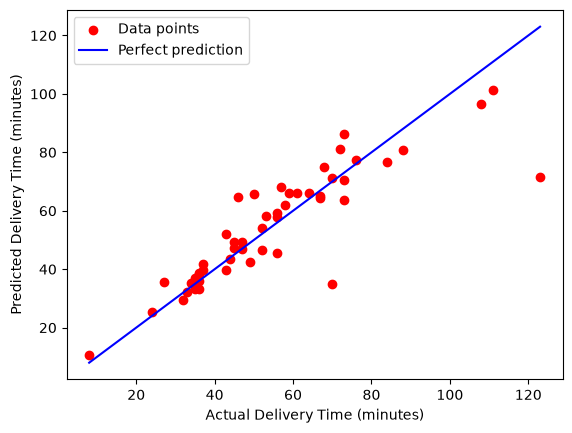

In [52]:
plt.scatter(Y_actual[:50], Y_pred[:50], color="Red", label="Data points")
plt.plot([Y_actual[:50].min(), Y_actual[:50].max()],
         [Y_actual[:50].min(), Y_actual[:50].max()], color="Blue", label="Perfect prediction")
plt.xlabel("Actual Delivery Time (minutes)")
plt.ylabel("Predicted Delivery Time (minutes)")
plt.legend()
plt.show()